<a href="https://colab.research.google.com/github/opeoluwaomotayo/fairxai-dashboard/blob/main/AnExplainable_AI_Framework_for_Transparent_and_Fair_Decision_Making_in_Digital_Public_Services.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install shap lime -q

In [ ]:
import numpy as np
import pandas as pd

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

import shap
import matplotlib.pyplot as plt

from lime.lime_tabular import LimeTabularExplainer

In [ ]:
adult = fetch_openml(name='adult', version=2, as_frame=True)
data = adult.frame.copy()

print("Initial Columns:")
print(data.columns)

Initial Columns:
Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'class'],
      dtype='object')


In [ ]:
from sklearn.datasets import fetch_openml
import pandas as pd

# Load fresh dataset
adult = fetch_openml(name='adult', version=2, as_frame=True)
data = adult.frame.copy()

# 🔍 DEBUG: Check columns
print("Columns:", data.columns)

# 🔥 Ensure correct column name
target_col = None
for col in data.columns:
    if 'class' in col.lower() or 'income' in col.lower():
        target_col = col

print("Detected target column:", target_col)

# ✅ Create income safely
data['income'] = data[target_col].astype(str).apply(
    lambda x: 1 if '>50K' in x else 0
)

# Drop original label
data.drop(columns=[target_col], inplace=True)

# Drop missing values
data.dropna(inplace=True)

# Encode categorical variables
data = pd.get_dummies(data, drop_first=True)

# 🔍 FINAL CHECK
print("Final columns:", data.columns)

if 'income' not in data.columns:
    raise Exception("❌ income STILL missing — stop execution")

print("✅ SUCCESS: income column exists")
print("Shape:", data.shape)

Columns: Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'class'],
      dtype='object')
Detected target column: class
Final columns: Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week', 'income', 'workclass_Local-gov',
       'workclass_Never-worked', 'workclass_Private', 'workclass_Self-emp-inc',
       'workclass_Self-emp-not-inc', 'workclass_State-gov',
       'workclass_Without-pay', 'education_11th', 'education_12th',
       'education_1st-4th', 'education_5th-6th', 'education_7th-8th',
       'education_9th', 'education_Assoc-acdm', 'education_Assoc-voc',
       'education_Bachelors', 'education_Doctorate', 'education_HS-grad',
       'education_Masters', 'education_Preschool', 'education_Prof-school',
       'education_Some-college', 'marital-status_Married-AF-spous

In [ ]:
X = data.drop(columns=['income'])
y = data['income']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    random_state=42
)

model.fit(X_train, y_train)

preds = model.predict(X_test)

print("=== BASE MODEL ===")
print(classification_report(y_test, preds))
print("Accuracy:", accuracy_score(y_test, preds))

=== BASE MODEL ===
              precision    recall  f1-score   support

           0       0.87      0.95      0.91      6803
           1       0.79      0.56      0.65      2242

    accuracy                           0.85      9045
   macro avg       0.83      0.75      0.78      9045
weighted avg       0.85      0.85      0.84      9045

Accuracy: 0.8539524599226092


In [ ]:
gender_cols = [col for col in X.columns if 'sex' in col.lower()]
print("Gender column:", gender_cols)

sensitive = X_test[gender_cols[0]].values

Gender column: ['sex_Male']


In [ ]:
def demographic_parity(y_pred, sensitive):
    return abs(y_pred[sensitive==1].mean() - y_pred[sensitive==0].mean())

dp_before = demographic_parity(preds, sensitive)
print("Before Mitigation:", dp_before)

Before Mitigation: 0.1556643797221995


In [ ]:
weights = np.ones(len(X_train))

# Stronger fairness correction
weights[X_train[gender_cols[0]] == 0] *= 1.8

model_fair = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    random_state=42
)

model_fair.fit(X_train, y_train, sample_weight=weights)

preds_fair = model_fair.predict(X_test)

print("=== FAIR MODEL ===")
print(classification_report(y_test, preds_fair))
print("Accuracy:", accuracy_score(y_test, preds_fair))

=== FAIR MODEL ===
              precision    recall  f1-score   support

           0       0.87      0.95      0.91      6803
           1       0.80      0.56      0.65      2242

    accuracy                           0.85      9045
   macro avg       0.83      0.75      0.78      9045
weighted avg       0.85      0.85      0.84      9045

Accuracy: 0.8543946932006633


In [ ]:
dp_after = demographic_parity(preds_fair, sensitive)

print("Before:", dp_before)
print("After:", dp_after)

Before: 0.1556643797221995
After: 0.1517147385145559


100%|===================| 18082/18090 [22:48<00:00]       

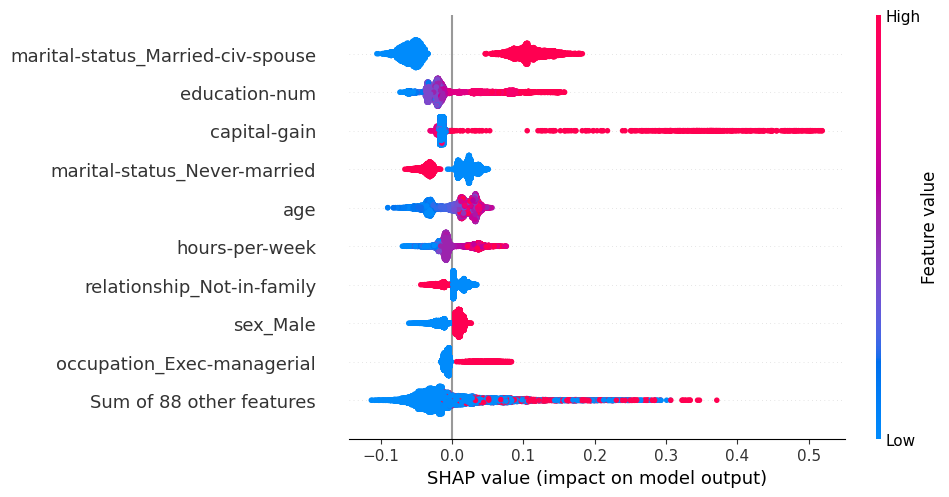

In [ ]:
import shap
import matplotlib.pyplot as plt
import numpy as np

# Convert data to float
X_train_float = X_train.astype(np.float64)
X_test_float = X_test.astype(np.float64)

# Create explainer
explainer = shap.Explainer(model_fair, X_train_float)

# Generate SHAP explanation object
shap_values = explainer(X_test_float)

# IMPORTANT: Select class 1 explanations only
shap_class1 = shap_values[:, :, 1]

# Generate beeswarm plot
shap.plots.beeswarm(
    shap_class1,
    max_display=10,
    show=False
)

# Save figure
plt.savefig(
    "shap_summary_final.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
explainer_lime = LimeTabularExplainer(
    X_train.values,
    feature_names=X.columns,
    class_names=['<=50K','>50K'],
    discretize_continuous=True
)

exp = explainer_lime.explain_instance(
    X_test.iloc[0].values,
    model_fair.predict_proba
)

exp.save_to_file("lime.html")